Started 2025 07 22 @ 21:42

Just trying to troubleshoot the RO issue like this here:
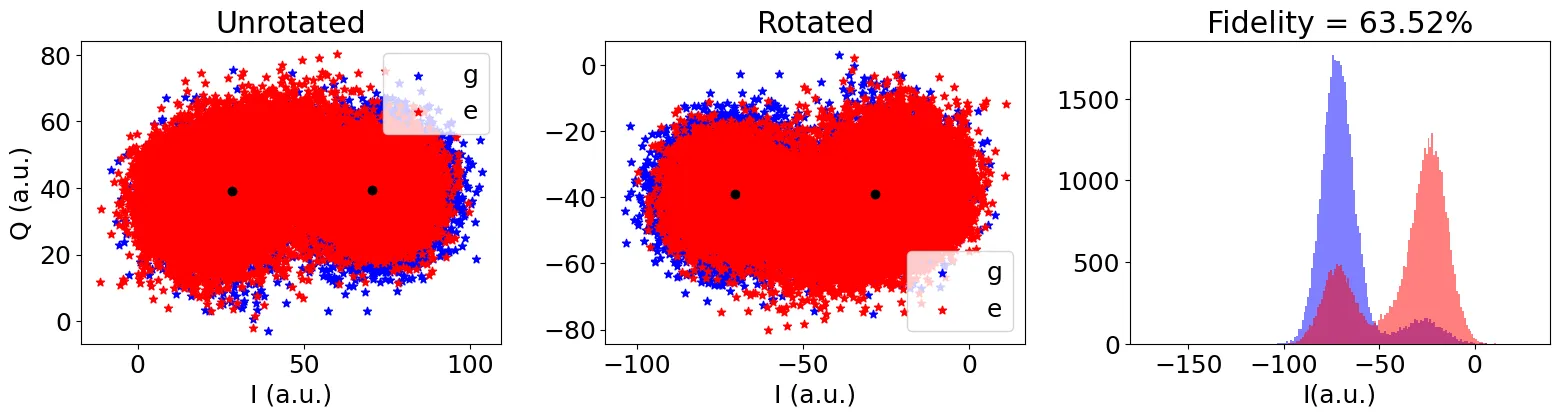

We don't understand the weird peak in the ground state.... ongoing issue im not going to type out here..

In [1]:
# jupyter setup boilerplate
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np


from fitting import *

import json
import datetime

from qualang_tools.plot import Fit

import pprint as pp

from plotting_helpers import *

%matplotlib inline
from pnax_msmts import *
from set_pulse_onoff import *
from malab import *

No module named 'visa'
Warning VISA library import failed
Warning serial library import failed.
Could not load InstrumentManagerWindow
2025-07-22 21:48:37,580 - qm - INFO     - Starting session: ef9fc28d-2b0a-4d9e-8c6a-05da649fa667
1024
YOKOGAWA,GS210,90Z317691,2.02
YOKOGAWA,GS210,90Z317691,2.02
Keysight Technologies,N5242B,MY58422393,A.13.60.06

Deviced Connected
Deviced Connected:
Keysight Technologies,N5242B,MY58422393,A.13.60.06



## add a dc block?
I thought it was there, apparently it has been removed at some point? Qihao suggested this after we looked at the spectrum, saw it was clean, and then probed the sma cable sending the signal with the volt meter -> resting bias voltage of around -0.1 V

In [2]:
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\single qubit characterization 3.95 GHz"
global_data_path = global_data_path + expt_path 

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\single qubit characterization 3.95 GHz\00002_IQ_plot_Q0_2025-07-22.h5
Optimal fidelity after rotation = 0.410


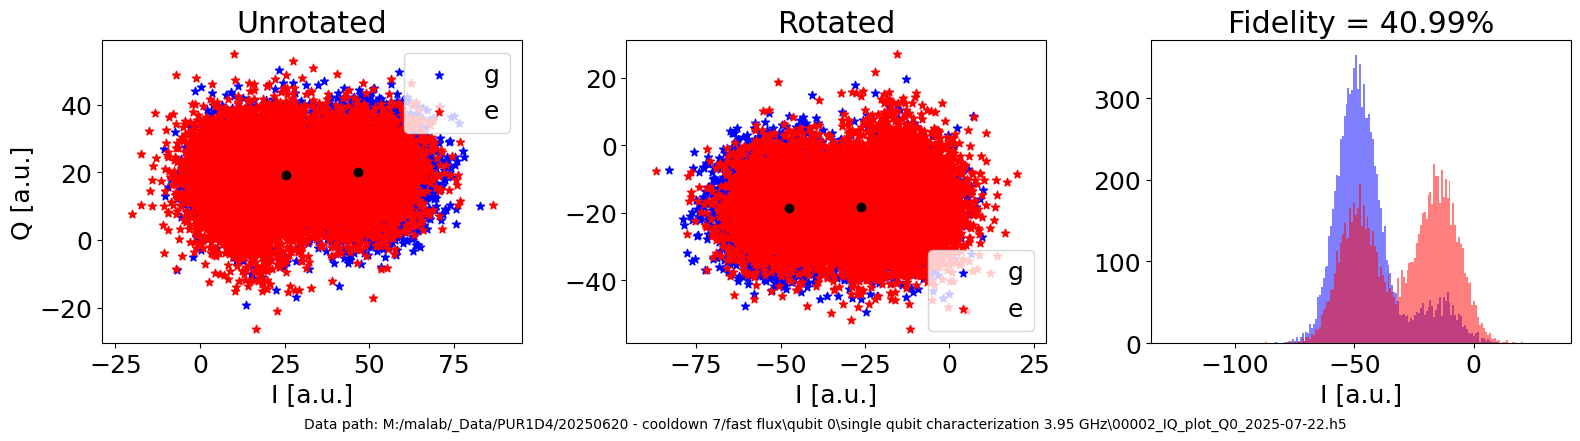

In [5]:
data = global_data_path + r"\00002_IQ_plot_Q0_2025-07-22.h5"

def plot_IQ_blob(data, ef=False):

    def hist(data=None, plot=True, ran=1.0):
    
        ig = data[0]
        qg = data[1]
        ie = data[2]
        qe = data[3]

        numbins = 200
        
        xg, yg = np.median(ig), np.median(qg)
        xe, ye = np.median(ie), np.median(qe)

        if plot==True:
            fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
            fig.tight_layout()

            axs[0].scatter(ig, qg, label='g', color='b', marker='*')
            axs[0].scatter(ie, qe, label='e', color='r', marker='*')
            axs[0].scatter(xg, yg, color='k', marker='o')
            axs[0].scatter(xe, ye, color='k', marker='o')
            axs[0].set_xlabel('I [a.u.]')
            axs[0].set_ylabel('Q [a.u.]')
            axs[0].legend(loc='upper right')
            axs[0].set_title('Unrotated')
            axs[0].axis('equal')
        """Compute the rotation angle"""
        theta = -np.arctan2((ye-yg),(xe-xg))
        """Rotate the IQ data"""
        ig_new = ig*np.cos(theta) - qg*np.sin(theta)
        qg_new = ig*np.sin(theta) + qg*np.cos(theta) 
        ie_new = ie*np.cos(theta) - qe*np.sin(theta)
        qe_new = ie*np.sin(theta) + qe*np.cos(theta)
        
        """New means of each blob"""
        xg, yg = np.median(ig_new), np.median(qg_new)
        xe, ye = np.median(ie_new), np.median(qe_new)
        
        #print(xg, xe)
        
        xlims = [xg-ran, xg+ran]
        ylims = [yg-ran, yg+ran]

        if plot==True:
            axs[1].scatter(ig_new, qg_new, label='g', color='b', marker='*')
            axs[1].scatter(ie_new, qe_new, label='e', color='r', marker='*')
            axs[1].scatter(xg, yg, color='k', marker='o')
            axs[1].scatter(xe, ye, color='k', marker='o')    
            axs[1].set_xlabel('I [a.u.]')
            axs[1].legend(loc='lower right')
            axs[1].set_title('Rotated')
            axs[1].axis('equal')

            """X and Y ranges for histogram"""
            
            ng, binsg, pg = axs[2].hist(ig_new, bins=numbins, range = xlims, color='b', label='g', alpha=0.5)
            ne, binse, pe = axs[2].hist(ie_new, bins=numbins, range = xlims, color='r', label='e', alpha=0.5)
            axs[2].set_xlabel('I [a.u.]')       
            
        else:        
            ng, binsg = np.histogram(ig_new, bins=numbins, range = xlims)
            ne, binse = np.histogram(ie_new, bins=numbins, range = xlims)

        """Compute the fidelity using overlap of the histograms"""
        contrast = np.abs(((np.cumsum(ng) - np.cumsum(ne)) / (0.5*ng.sum() + 0.5*ne.sum())))
        tind=contrast.argmax()
        threshold=binsg[tind]
        fid = contrast[tind]
        axs[2].set_title(f"Fidelity = {fid*100:.2f}%")

        return fid, threshold, theta, fig


    with SlabFile(data, 'r') as f:
        I_g = array(f['I_g'])[0]
        Q_g = array(f['Q_g'])[0]
        I_e = array(f['I_e'])[0]
        Q_e = array(f['Q_e'])[0]
        if ef == True:
            I_f = array(f['I_f'])[0]
            Q_f = array(f['Q_f'])[0]
        config = f.attrs['config']
        config = json.loads(config)

    print('Data path:', data)

    fid, threshold, angle, fig = hist(data=[I_g, Q_g, I_e, Q_e],  plot=True, ran=80)
    print('Optimal fidelity after rotation = %.3f' % fid)
    plt.figtext(0.5, -0.06, 'Data path: '+str(data), ha="center", fontsize=10)

    return fig, [fid, threshold, angle], config

plot, fits, config = plot_IQ_blob(data)
# print(fits)
# print(config)

res_gain_ge = 0.003
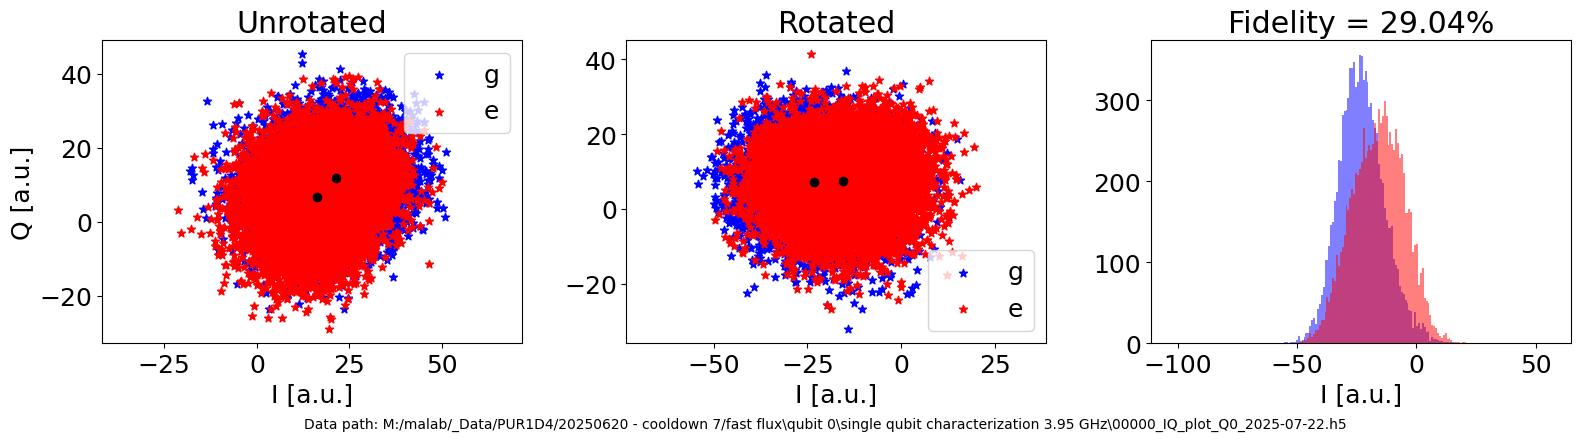


res_gain_ge = 0.007
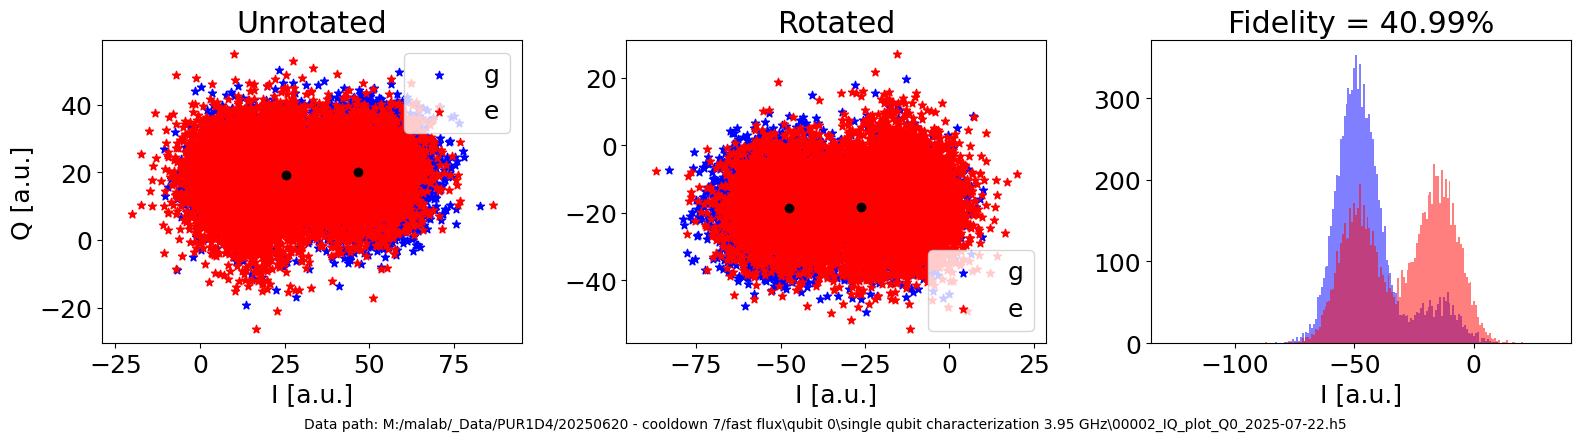


res_gain_ge = 0.01
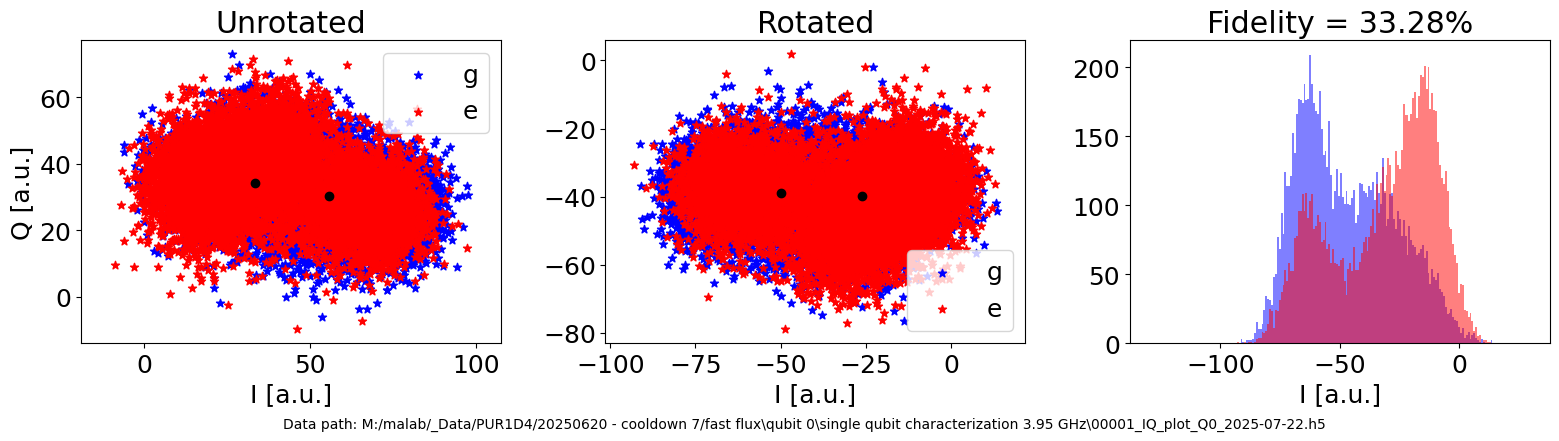


definitely changed, will need to redo single qubit characterization now...